#  Больше практических инструментов

## Время

При реализации задач часто важно не только получить правильный ответ, но и понять, насколько быстро работает программа. Как мы уже выяснили, теоретически это можно сделать, посчитав асимптотику. Обычно чем асимптотика решения меньше, тем программа быстрее работает. Но иногда важны неасимптотические оптимизации: важно, насколько быстро ваше решение работает на практике. В таком случае нужно физически измерить, сколько секунд работает программа.

Например, у нас есть два способа найти сумму чисел от 1 до миллиона:

In [1]:
n = 1_000_000

# Первый способ
s = 0
for i in range(1, n + 1):
    s += i

# Второй способ
s = sum(range(1, n + 1))

Оба способа дают одинаковый результат, но работают с разной скоростью. Давайте убедимся в этом с помощью модуля `time`, который содержит одноименную функцию `time()`.

In [7]:
import time

In [8]:
n = 1_000_000

start = time.time()
s = 0
for i in range(1, n + 1):
    s += i
end = time.time()
print("for:", end - start, "sec")


start = time.time()
s = sum(range(1, n + 1))
end = time.time()
print("sum:", end - start, "sec")

for: 0.14030241966247559 sec
sum: 0.016454696655273438 sec


Мы видим, что встроенная функция `sum` более оптимизирована и работает быстрее.

`time.time()` - возвращает текущее время в секундах с начала эпохи Unix (1 января 1970 года). Можно использовать для получения текущей временной отметки. Поэтому, чтобы замерить кусок программы, нужно замерить время до ее выполнения и после, тогда разность двух величин и будет временем выполнения программы.

Чтобы не повторять код измерения времени, можно написать отдельную функцию:

In [4]:
def measure_time(func):
    start = time.perf_counter()
    func()
    end = time.perf_counter()
    return end - start

In [5]:
def slow():
    s = 0
    for i in range(10_000_000):
        s += i


def fast():
    s = sum(range(10_000_000))


print("slow work in time", measure_time(slow), "sec")
print("fast work in time", measure_time(fast), "sec")

slow work in time 0.4044636000000139 sec
fast work in time 0.16838659999999095 sec


Тут вместо `time()` используется `time.perf_counter()`, эта функция возвращает значение высокоточного счётчика времени. Лучше всего подходит для измерения продолжительности выполнения небольших фрагментов программы.

**Важно:** время одного запуска не всегда объективно показывает скорость программы. На результат влияют другие запущенные программы, загрузка процессора и особенности компьютера. Для более точного сравнения стоит проводить несколько запусков и сравнивать результаты.

## Рандом

Мы с вами рассматривали *детерминированные* программы, то есть такие программы, которые выполняют фиксированные действия с данными вне зависимости от того, сколько раз и когда запускать программу. Но иногда полезно делать что-то непредсказуемое, случайное. Для этого используются случайные числа. С их помощью можно:

- моделировать броски кубика и другие эксперименты;
- выполнять симуляции и использовать в компьютерных играх;
- моделировать физические и экономические процессов;
- создавать случайные тесты для алгоритмов;
- создавать вероятностные алгоритмы, которые работают с большой вероятностью эффективно; 
- перемешивать данные.


Важно понимать, что обычный компьютер не генерирует настоящую случайность. Он использует **псевдослучайный генератор**: последовательность чисел, которая выглядит случайной, но определяется внутренним состоянием генератора.

Приведем пример псевдослучайного генератора:

In [5]:
# Выбираем большие числа от балды - состояние генератора
A = 457834754
B = 123678463
curr = 943678453
mod = 1647859323

def PseudoRandom():
    global curr # нужно, чтобы работать с внешней переменной curr внутри функции 
    curr = (A * curr + B) % mod
    return curr

print(*[PseudoRandom() % 100 for i in range(10)])

95 53 31 31 64 59 35 48 12 69


Данные числа выглядят вполне случайными, однако каждое число получается по строгим правилам. То есть никакой случайности по сути нет, но полученные числа уже можно воспринимать как рандомные. Более того при использовании `PseudoRandom` в других ячейках, повторные запуски программы будет получать разные значения рандома.


Однако в Python для генерации случайных чисел существует модуль `random`.

In [19]:
import random

| Функция | Что делает |
|---|---|
| `random.random()` | Число с плавающей точкой от 0 до 1, не включая 1 |
| `random.randint(a, b)` | Случайное целое от `a` до `b` включительно |
| `random.randrange(a, b)` | Случайное целое из диапазона от `a` до `b`, не включая `b` |
| `random.uniform(a, b)` | Случайное вещественное число между `a` и `b` |
| `random.choice(seq)` | Случайный элемент последовательности |
| `random.choices(seq, k=n)` | Выбор `n` элементов с возвращением |
| `random.sample(seq, k)` | Выбор `k` различных элементов без возвращения |
| `random.shuffle(seq)` | Перемешивание списка на месте |
| `random.seed(x)` | Установка начального состояния генератора |

Все данные функции можно реализовать и с помощью нашего `PseudoRandom`, но проще пользоваться встроенными.

### Пример 1. Бросок кубика

In [20]:
dice = random.randint(1, 6)

print("Выпало:", dice)

Выпало: 3


Каждый запуск программы может выдавать новое число от 1 до 6.

### Пример 2. Случайный выбор

Представим, что мы хотим случайным образом выбрать человека для ответа на уроке:

In [26]:
students = ["Сафия", "Иван", "Георгий", "Максим", "Кирилл", "Миша", "Даниил", "Полина", "Михаил", "Илья", "Юрий", "Аля", "Клим", "Саша"]
print("Сегодня отвечает:", random.choice(students))
print("Командный проект будут выполнять:", *random.sample(students, 3))

Сегодня отвечает: Иван
Командный проект будут выполнять: Максим Илья Даниил


При использовании `sample` один и тот же участник не может попасть в выборку дважды, в отличие от случая, когда мы генерируем участников через `choice`.

### Пример 3. Перемешивание списка

In [29]:
cards = ["туз", "король", "дама", "валет"]
random.shuffle(cards)
print(cards)

['король', 'дама', 'валет', 'туз']


Функция `shuffle` изменяет исходный список и ничего не возвращает.

### Пример 4. Взвешенный случайный выбор

In [ ]:
items = ["обычный", "редкий", "эпический", "легендарный"]

pack = random.choices(
    items,
    weights=[70, 20, 9, 1],
    k=5
)

print(pack)

['редкий', 'обычный', 'обычный', 'эпический', 'обычный']


Сумма весов равна 100, поэтому вероятности составляют соответственно 70%, 20%, 9% и 1%.
При этом веса не обязаны в сумме давать 100. Важны только их относительные значения.

### Пример 5. Рандом в алгоритмах

С помощью рандома вычислим примерную площадь круга с центром в $(0, 0)$ радиуса $1$.

Для этого на плоскость накидаем $1000000$ случайных точек. Теория вероятностей нам подсказывает, что точка попадет в круг с вероятностью $S_{круга}/S_{пространства}$. Тогда можно посчитать, сколько точек попало в круг, и получить приближенное значение площади:

In [36]:
import math

N = 1_000_000
points = [(random.uniform(-1, 1), random.uniform(-1, 1)) for _ in range(N)]
print(len(list(filter(lambda p: (p[0]**2 + p[1]**2 <= 1), points))) / N * 4)
print(math.pi)

3.141248
3.141592653589793


Данный метод называется методом *Монте-Карло*. Когда время работы алгоритма фиксированное, но ответ выдается с погрешностью.

Еще существует метод *Лас Вегас*, который выдает правильный результат, но может выполняться долго по времени.


### Начальное состояние генератора: random.seed()

Иногда важно, чтобы программа генерировала одну и ту же последовательность случайных чисел при каждом запуске.

Для этого используется функция `random.seed()`.

In [38]:
import random

random.seed(42)

for i in range(5):
    print(random.randint(1, 100))

82
15
4
95
36


Если запустить эту программу несколько раз, последовательность будет одинаковой.

Если убрать `random.seed(42)`, генератор обычно будет использовать автоматически выбранное начальное состояние, и последовательность между запусками будет отличаться.

Такое может пригодиться при тестировании программ.

Представим, что мы хотим найти ошибку в программе, для этого мы написали программу, которая генерирует случайные тесты. И на одном из них нашёлся неправильный ответ. Вы пофиксили программу и хотите снова проверить ее. Чтобы понять, исправлена ли ошибка, нужно получить точно такой же тест. Для этого можно зафиксировать начальное состояние генератора.

### Распределения

Иногда нужно генерировать значения с разной вероятностью, как мы видели в примере 4. В дискретном случае (когда различных значений конечное число), можно задать вероятность выпадения каждого значения. Однако, когда значений бесконечное количество, например вещественные числа на отрезке $[0, 1]$, вероятность каждого числа задать не получится. В этом случае обращаются к **распределениям**. Распределение обычно задается *функцией распределения* $F(x) = \mathbb{P}[\xi < x]$ - с какой вероятностью результат случайной величины будет меньше $x$. Случайные числа, они же случайные величины обычно обозначаются греческими буквами, например $\xi$.

Например, равномерное распределение на отрезке $[a, b]$, которое генерирует функция `random.uniform(a, b)`, имеет функцию распределения $F(x) = (x - a) / (b - a)$ при $x \in [a, b]$.

Задавать распределение можно не только функцией распределения, но и функцией плотности: $f(x) = F'(x)$. Плотность - это аналог вероятностей в дискретном случае, то есть относительная вероятность реализации тех или иных значений случайной величины.

В случае нормального распределения "вероятность" каждого значения одинакова $f(x) = 1/(b-a)$

Но иногда нам нужны другие распределения, например, если мы хотим сгенерировать рост случайного взрослого человека, то скорее всего с большой вероятностью рост будет в промежутке от 160 до 180, реже будут встречаться люди с ростом 200 и 140. Поэтому давать каждому росту одинаковую (плотность) вероятность неправдоподобно. Тут обычно на помощь приходит **нормальное распределение** со страшной функцией плотности $f(x) = \dfrac{exp\big(-\dfrac{(x - \mu)^2}{2\sigma^2}\big)}{\sqrt{2 \pi} \sigma}$, где $exp(x) = e^x$, $\mu$ - среднее значение распределения, $\sigma$ - среднеквадратичное отклонение, которое показывает, на сколько значения будут рассеяны (отклонены от среднего). Функция распределения у нормального распределения тоже есть, но она записывается сильно сложнее: $F(x) = \dfrac{1}{\sqrt{2\pi}} \int \limits_{-\infty}^{(x - \mu)/\sigma} e^{-t^2/2} dt$

Формула - это, конечно, хорошо, но для понимания лучше посмотреть на графики плотности и распределения:  

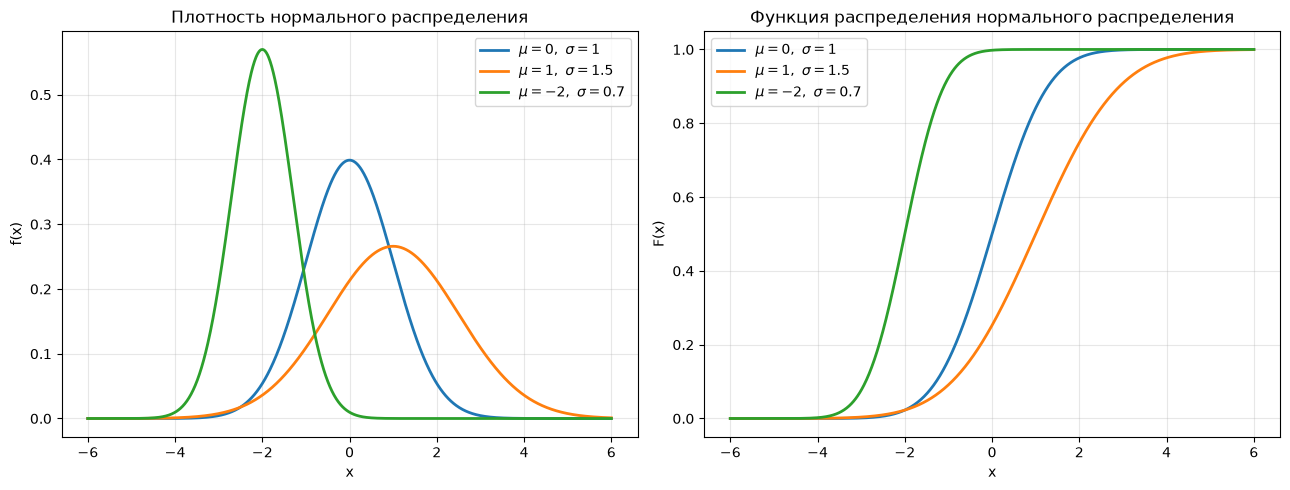

In [2]:
import math
import matplotlib.pyplot as plt

params = [
    (0,  1.0, 'tab:blue',   r'$\mu=0,\ \sigma=1$'),
    (1,  1.5, 'tab:orange', r'$\mu=1,\ \sigma=1.5$'),
    (-2, 0.7, 'tab:green',  r'$\mu=-2,\ \sigma=0.7$'),
]

def normal_f(x, mu, sigma):
    return math.exp(-((x - mu) ** 2) / (2 * sigma ** 2)) / (sigma * math.sqrt(2 * math.pi))

def normal_F(x, mu, sigma):
    return 0.5 * (1 + math.erf((x - mu) / (sigma * math.sqrt(2))))

n = 1000
x_min, x_max = -6.0, 6.0
xs = [x_min + (x_max - x_min) * i / (n - 1) for i in range(n)]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))


for mu, sigma, color, label in params:
    ys = [normal_f(x, mu, sigma) for x in xs]
    axes[0].plot(xs, ys, color=color, lw=2, label=label)

axes[0].set_title('Плотность нормального распределения')
axes[0].set_xlabel('x')
axes[0].set_ylabel('f(x)')
axes[0].grid(True, alpha=0.3)
axes[0].legend()


for mu, sigma, color, label in params:
    ys = [normal_F(x, mu, sigma) for x in xs]
    axes[1].plot(xs, ys, color=color, lw=2, label=label)

axes[1].set_title('Функция распределения нормального распределения')
axes[1].set_xlabel('x')
axes[1].set_ylabel('F(x)')
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()

Такое распределение может подойти для генерации роста человека. Считаем, что средний рост - 170, отклонение 10. 

In [43]:
print(*[random.gauss(170, 10) for _ in range(10)])

170.17593105583575 175.4796164633998 183.1387319446209 179.8642162864945 157.17656557156894 166.2424013376335 174.34760334259428 170.87992903529445 171.4759598253599 183.4941323966315


Иногда встречаются низкие и высокие люди, но в основном все примерно 170 сантиметров.

Также бывает экспоненциальное распределение и много других. Для некоторых из них есть генераторы в `random`, а библиотека `scipy.stats` предоставляет большой набор статистических распределений, чего мы не будем пока касаться.

### Тестирование алгоритмов

Один из полезных способов применения генератора случайных чисел в программировании - **автоматическое тестирование алгоритмов**.

Когда мы решаем алгоритмическую задачу, часто проверяем программу на нескольких примерах вручную. Но несколько примеров не гарантируют, что программа работает правильно на всех возможных входных данных.

Особенно сложно найти ошибки, которые возникают только на редких комбинациях чисел.

Для этого можно генерировать большое количество случайных тестов.

In [ ]:
def my_max(a):
    ans = 0
    for x in a:
        if x > ans:
            ans = x
    return ans

for test in range(1000):
    n = random.randint(1, 100)
    a = [random.randint(-1000, 1000) for i in range(n)]
    
    answer = my_max(a)
    correct = max(a)

    if answer != correct:
        print("Error on test:", a, ", expected:", correct, ", found:", answer)
        break
else:
    print("Tests passed!")

Error on test: [-451] , expected: -451 , found: 0


Обычно для проверки нужна эталонная функция, которая будет работать **гарантированно верно** (но не обязательно оптимально). Полезно запускать вашу функцию на маленьких тестах, чтобы вы смогли руками разобрать где ошибка.

Если вы используете `random.seed()`, то сможете воспроизвести последовательность тестов.

## Обработка ошибок

При выполнении программы иногда возникают ошибки.

Например:
- пользователь ввёл текст вместо числа;
- программа пытается открыть несуществующий файл;
- мы пытаемся разделить число на ноль;
- обращаемся к элементу списка, которого не существует.

Если такие ошибки не обработать, программа может аварийно завершиться.

В Python для обработки подобных ситуаций используются конструкции `try` и `except`:

```python
try:
    # Код, в котором может произойти ошибка
    ...
except:
    # Код, который выполнится при ошибке
    ...
```
Python сначала выполняет код внутри `try`.

- Если ошибки не произошло, блок `except` пропускается.
- Если произошла ошибка, выполнение блока `try` прекращается и Python переходит в подходящий `except`.

In [47]:
try:
    x = int(input())
    print("Number:", x)
except:
    print("Error! Could not convert input to int")

Error! Could not convert input to int


Если пользователь введёт `123`, блок `try` отработает и выведет `Number: 123`.

Если пользователь введёт `hello`, преобразование `int("hello")` вызовет ошибку, и выполнится блок `except`.

### Разные типы исключений

В Python разные ошибки представлены разными типами исключений.

Некоторые распространённые исключения:

| Исключение | Когда возникает |
|---|---|
| `ValueError` | Неподходящее значение, например `int("abc")` |
| `ZeroDivisionError` | Деление на ноль |
| `FileNotFoundError` | Файл не найден |
| `IndexError` | Выход за границы списка |
| `KeyError` | Несуществующий ключ словаря |
| `TypeError` | Операция применяется к объекту неподходящего типа |

Вместо того чтобы перехватывать вообще все ошибки, обычно лучше указывать конкретные типы исключений.

In [49]:
try:
    a = float(input())
    b = float(input())

    print(a / b)

except ValueError:
    print("Error! Could not convert input to float")

except ZeroDivisionError:
    print("Error! Could not divide by zero")

Error! Could not divide by zero


Теперь программа отдельно обрабатывает две ситуации:
- пользователь ввёл не число;
- пользователь попытался разделить на ноль.

In [50]:
try:
    with open("data.txt", "r", encoding="utf-8") as f:
        text = f.read()

    print(text)

except FileNotFoundError:
    print("File not found!")

except PermissionError:
    print("Read permission denied!")

File not found!



У конструкции обработки исключений есть ещё два блока: `else` и `finally`.

Полный синтаксис:

```python
try:
    ...
except SomeError:
    ...
else:
    ...
finally:
    ...
```

- `try` — код, в котором может произойти исключение.
- `except` — обработка исключения.
- `else` — выполняется, если в блоке `try` не было исключения.
- `finally` — выполняется в любом случае: произошла ошибка или нет.

In [9]:
try:
    x = int(input())

except ValueError:
    print("Could not convert input to int!")

else:
    print("Successfully read:", x)
    print("Square:", x * x)

Successfully read: 3
Square: 9


### Генерация исключений

Иногда ошибка возникает не из-за Python, а из-за того, что мы сами обнаружили неправильные данные.

Например, функция должна принимать только положительное число. Если передали отрицательное, можно самостоятельно вызвать исключение с помощью `raise`.

In [3]:
def square_root(x):
    if x < 0:
        raise ValueError("The square root of a negative number is undefined")
    return x ** 0.5


try:
    print(square_root(-5))
except ValueError as error:
    print("Error:", error)

Error: The square root of a negative number is undefined


Когда мы перехватываем ошибку, например `ValueError`, как в данном случае, мы можем получить её сообщение. Для этого нужно написать `as` и указать переменную, в которую будет записан текст ошибки.

In [4]:
try:
    int("hello")
except Exception as error:
    print(error)

invalid literal for int() with base 10: 'hello'


`Exception` ловит любую ошибку. Но лучше пользоваться конкретными ошибками.